# Federated learning on PlantVillage crops
3 CNNs (ResNet50, VGG16, MobileNetV2) x 4 crops (Grape, Apple, Corn, Tomato) = 12 experiments.
FedAvg with 3 clients, 30 rounds. The last cell plots which model comes out on top.

In [1]:
%pip install -q pandas scikit-learn "matplotlib>=3.7" pillow torch torchvision

Note: you may need to restart the kernel to use updated packages.


In [2]:
import gc, os, random, re, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import models, transforms

# ---- settings ----
SEED = 42
NUM_CLIENTS = 3
LOCAL_EPOCHS = 1
ROUNDS = 30
BATCH_SIZE = 16
LR = 0.01
IMG_SIZE = 224
NUM_WORKERS = 0          # 0 is the safest on Windows

# change these two for your machine
DATA_ROOT = Path(r"C:\Users\ADK\Downloads\PlantVillage")
OUT_DIR = Path(r"C:\Users\ADK\Downloads\fl_crop_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# everything gets saved under OUT_DIR:
#   values/       -> all csv tables
#   graphs/       -> all comparison plots
#   experiments/  -> one folder per (crop, model) with its own csv + curves
VALUES_DIR = OUT_DIR / "values"
GRAPHS_DIR = OUT_DIR / "graphs"
EXPS_DIR = OUT_DIR / "experiments"
for d in (VALUES_DIR, GRAPHS_DIR, EXPS_DIR):
    d.mkdir(exist_ok=True)

MODELS = ["ResNet50", "VGG16", "MobileNetV2"]
CROPS = ["Grape", "Apple", "Corn", "Tomato"]

CROP_ALIASES = {"Grape": ("grape",), "Apple": ("apple",),
                "Corn": ("corn", "maize"), "Tomato": ("tomato",)}
EXPECTED_CLASSES = {"Grape": 4, "Apple": 4, "Corn": 4, "Tomato": 10}
PAPER_TOTALS = {"Grape": 4062, "Apple": 3161, "Corn": 3852, "Tomato": 18160}
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cpu":
    print("Warning: no GPU found, 12 experiments will be slow.")

for split in ("train", "val"):
    if not (DATA_ROOT / split).is_dir():
        raise FileNotFoundError(f"missing folder: {DATA_ROOT / split}")


def seed_everything(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()

Device: cuda


## Finding the crop folders

In [3]:
def norm(text):
    return re.sub(r"[^a-z0-9]+", "_", text.casefold()).strip("_")


def has_images(folder):
    return any(p.suffix.lower() in IMG_EXT for p in folder.rglob("*") if p.is_file())


def find_class_dirs(split, crop):
    # handles both  train/Grape/<class>/  and  train/Grape___Black_rot/
    aliases = [norm(a) for a in CROP_ALIASES[crop]]
    found = []
    for top in sorted((DATA_ROOT / split).iterdir()):
        if not top.is_dir():
            continue
        token = norm(top.name)
        subdirs = sorted(p for p in top.iterdir() if p.is_dir())
        if token in aliases and subdirs:
            found.extend(subdirs)
        elif any(a in token for a in aliases):
            found.append(top)
    found = [d for d in dict.fromkeys(found) if has_images(d)]
    if not found:
        raise RuntimeError(f"no class folders for {crop} in {split}")
    return found


def check_crop(crop):
    train_dirs = find_class_dirs("train", crop)
    val_dirs = find_class_dirs("val", crop)
    train_names = {d.name for d in train_dirs}
    val_names = {d.name for d in val_dirs}
    if train_names != val_names:
        raise ValueError(f"{crop}: train/val classes differ")
    if len(train_names) != EXPECTED_CLASSES[crop]:
        raise ValueError(f"{crop}: got {len(train_names)} classes, expected {EXPECTED_CLASSES[crop]}")
    print(f"{crop}: {len(train_names)} classes -> {sorted(train_names)}")
    return train_dirs, val_dirs


for crop in CROPS:
    check_crop(crop)

Grape: 4 classes -> ['Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy']
Apple: 4 classes -> ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy']
Corn: 4 classes -> ['Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy']
Tomato: 10 classes -> ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']


## Dataset, normalisation and client splits

In [4]:
class CropDataset(Dataset):
    def __init__(self, class_dirs, class_to_idx=None, transform=None):
        names = sorted(d.name for d in class_dirs)
        self.class_to_idx = class_to_idx or {n: i for i, n in enumerate(names)}
        self.classes = sorted(self.class_to_idx, key=self.class_to_idx.get)
        self.transform = transform
        self.samples = []
        for d in class_dirs:
            label = self.class_to_idx[d.name]
            files = sorted(p for p in d.rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXT)
            self.samples += [(p, label) for p in files]
        if not self.samples:
            raise RuntimeError("no images found")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, i):
        path, label = self.samples[i]
        with Image.open(path) as img:
            img = img.convert("RGB")
            if self.transform:
                img = self.transform(img)
        return img, label


def rgb_mean_std(dataset):
    # mean/std of the training images only (no leakage from val)
    loader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=NUM_WORKERS)
    s = torch.zeros(3, dtype=torch.float64)
    sq = torch.zeros(3, dtype=torch.float64)
    n = 0
    for x, _ in loader:
        x = x.double()
        s += x.sum(dim=(0, 2, 3))
        sq += (x * x).sum(dim=(0, 2, 3))
        n += x.shape[0] * x.shape[2] * x.shape[3]
    mean = s / n
    std = (sq / n - mean ** 2).clamp_min(1e-12).sqrt()
    return mean.tolist(), std.tolist()


def load_crop(crop):
    train_dirs, val_dirs = check_crop(crop)

    plain = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor()])
    raw = CropDataset(train_dirs, transform=plain)
    print("computing mean/std...")
    mean, std = rgb_mean_std(raw)

    tf = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)),
                             transforms.ToTensor(),
                             transforms.Normalize(mean, std)])
    train_ds = CropDataset(train_dirs, raw.class_to_idx, tf)
    val_ds = CropDataset(val_dirs, raw.class_to_idx, tf)

    total = len(train_ds) + len(val_ds)
    print(f"{crop}: train={len(train_ds):,} val={len(val_ds):,} total={total:,}")
    if total != PAPER_TOTALS[crop]:
        print(f"  note: paper says {PAPER_TOTALS[crop]:,} images, you have {total:,}")
    return train_ds, val_ds, len(raw.classes)


def split_clients(dataset, seed):
    # equal random (IID) split across clients
    g = torch.Generator().manual_seed(seed)
    idx = torch.randperm(len(dataset), generator=g).numpy()
    parts = np.array_split(idx, NUM_CLIENTS)
    loaders = []
    for k, part in enumerate(parts):
        gen = torch.Generator().manual_seed(seed + 1000 + k)
        loaders.append(DataLoader(Subset(dataset, part.tolist()), batch_size=BATCH_SIZE,
                                  shuffle=True, num_workers=NUM_WORKERS,
                                  pin_memory=(DEVICE.type == "cuda"), generator=gen))
    return loaders, [len(p) for p in parts]

## Models and the federated part

In [5]:
def make_model(name, num_classes, pretrained=True):
    if name == "ResNet50":
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    elif name == "VGG16":
        m = models.vgg16(weights=models.VGG16_Weights.DEFAULT if pretrained else None)
        m.classifier[6] = nn.Linear(m.classifier[6].in_features, num_classes)
    elif name == "MobileNetV2":
        m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT if pretrained else None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
    else:
        raise ValueError(f"unknown model {name}, pick from {MODELS}")
    return m


def cpu_state(model):
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}


def train_client(model, global_state, loader):
    # model is reused between clients, we just reset it to the global weights
    model.load_state_dict(global_state)
    model.train()
    opt = torch.optim.SGD(model.parameters(), lr=LR)
    loss_fn = nn.CrossEntropyLoss()
    for _ in range(LOCAL_EPOCHS):
        for x, y in loader:
            if x.size(0) < 2:      # BatchNorm can't train on a batch of 1
                continue
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss_fn(model(x), y).backward()
            opt.step()
    return cpu_state(model)


def fedavg(states, sizes, reference):
    # weighted average by number of local samples
    w = [s / sum(sizes) for s in sizes]
    out = {}
    for key, ref in reference.items():
        if torch.is_floating_point(ref):
            avg = torch.zeros_like(ref, dtype=torch.float64)
            for wi, st in zip(w, states):
                avg += wi * st[key].double()
            out[key] = avg.to(ref.dtype)
        else:
            out[key] = ref.clone()   # e.g. BatchNorm num_batches_tracked
    return out


@torch.no_grad()
def evaluate(model, loader):
    # note: the val folder is used as the test set here (no separate test split)
    model.eval()
    y_true, y_pred = [], []
    for x, y in loader:
        pred = model(x.to(DEVICE)).argmax(dim=1).cpu()
        y_true += y.tolist()
        y_pred += pred.tolist()
    return {"accuracy": accuracy_score(y_true, y_pred),
            "f1": f1_score(y_true, y_pred, average="weighted", zero_division=0)}


def run_federated(model_name, num_classes, train_loaders, sizes, val_loader):
    global_model = make_model(model_name, num_classes).to(DEVICE)
    local_model = make_model(model_name, num_classes, pretrained=False).to(DEVICE)
    history = []

    for rnd in range(1, ROUNDS + 1):
        t0 = time.perf_counter()
        global_state = cpu_state(global_model)

        local_states = []
        for k, loader in enumerate(train_loaders, 1):
            print(f"  round {rnd:02d}/{ROUNDS} client {k}/{NUM_CLIENTS}", end="\r")
            local_states.append(train_client(local_model, global_state, loader))

        global_model.load_state_dict(fedavg(local_states, sizes, global_state))
        m = evaluate(global_model, val_loader)
        secs = time.perf_counter() - t0
        history.append({"round": rnd, "accuracy": m["accuracy"], "f1": m["f1"], "seconds": secs})
        print(f"  round {rnd:02d}/{ROUNDS}  acc={m['accuracy']*100:.2f}%  "
              f"f1={m['f1']*100:.2f}%  ({secs:.0f}s)          ")

        del global_state, local_states
        gc.collect()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    return pd.DataFrame(history)

## Running one experiment

In [6]:
def exp_dir(crop, model_name):
    return EXPS_DIR / f"{norm(crop)}__{norm(model_name)}"


def save_results(crop, model_name, history, n_classes):
    d = exp_dir(crop, model_name)
    d.mkdir(parents=True, exist_ok=True)
    history.to_csv(d / "per_round_results.csv", index=False)

    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(history["round"], history["accuracy"] * 100, marker="o", ms=3, label="Accuracy")
    ax.plot(history["round"], history["f1"] * 100, marker="s", ms=3, label="F1")
    ax.set(xlabel="Communication round", ylabel="%", title=f"{crop} + {model_name}")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.savefig(d / "curves.png", dpi=200, bbox_inches="tight")
    plt.close(fig)

    last = history.iloc[-1]
    summary = {"Dataset": crop, "Model": model_name, "Classes": n_classes,
               "Rounds": ROUNDS, "Accuracy": last["accuracy"], "F1": last["f1"]}
    pd.DataFrame([summary]).to_csv(d / "summary.csv", index=False)
    return summary


def run_experiment(crop, model_name):
    seed_everything(SEED)
    train_ds, val_ds, n_classes = load_crop(crop)

    train_loaders, sizes = split_clients(train_ds, SEED)
    val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, num_workers=NUM_WORKERS)

    history = run_federated(model_name, n_classes, train_loaders, sizes, val_loader)
    return save_results(crop, model_name, history, n_classes)

## Run all 12 (already finished ones are skipped, so you can restart safely)

In [7]:
EXPERIMENTS = [(c, m) for m in MODELS for c in CROPS]
summaries = []

for i, (crop, model_name) in enumerate(EXPERIMENTS, 1):
    print("\n" + "#" * 70)
    print(f"Experiment {i}/{len(EXPERIMENTS)}: {crop} + {model_name}")
    print("#" * 70)

    done = exp_dir(crop, model_name) / "summary.csv"
    if done.exists():
        print("already done, loading saved result")
        summaries.append(pd.read_csv(done).iloc[0].to_dict())
        continue

    t0 = time.time()
    s = run_experiment(crop, model_name)
    summaries.append(s)
    print(f"-> acc {s['Accuracy']*100:.2f}%  f1 {s['F1']*100:.2f}%  ({(time.time()-t0)/60:.1f} min)")

results = pd.DataFrame(summaries)
results.to_csv(VALUES_DIR / "all_12_experiments_summary.csv", index=False)
results


######################################################################
Experiment 1/12: Grape + ResNet50
######################################################################
Grape: 4 classes -> ['Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy']
computing mean/std...
Grape: train=3,251 val=811 total=4,062
  round 01/30  acc=92.11%  f1=91.63%  (36s)          
  round 02/30  acc=97.90%  f1=97.90%  (33s)          
  round 03/30  acc=98.03%  f1=98.02%  (33s)          
  round 04/30  acc=98.89%  f1=98.89%  (33s)          
  round 05/30  acc=98.77%  f1=98.77%  (34s)          
  round 06/30  acc=99.26%  f1=99.26%  (33s)          
  round 07/30  acc=99.26%  f1=99.26%  (33s)          
  round 08/30  acc=99.14%  f1=99.14%  (33s)          
  round 09/30  acc=99.51%  f1=99.51%  (33s)          
  round 10/30  acc=99.26%  f1=99.26%  (34s)          
  round 11/30  acc=99.26%  f1=99.26%  (33s)          
  round 12/30  acc=99.38%  f1

100%|██████████| 528M/528M [01:00<00:00, 9.14MB/s] 


  round 01/30  acc=73.74%  f1=72.35%  (52s)          
  round 02/30  acc=98.15%  f1=98.15%  (51s)          
  round 03/30  acc=99.01%  f1=99.01%  (51s)          
  round 04/30  acc=97.16%  f1=97.15%  (51s)          
  round 05/30  acc=99.14%  f1=99.14%  (50s)          
  round 06/30  acc=99.63%  f1=99.63%  (50s)          
  round 07/30  acc=99.14%  f1=99.14%  (50s)          
  round 08/30  acc=99.75%  f1=99.75%  (50s)          
  round 09/30  acc=99.14%  f1=99.14%  (51s)          
  round 10/30  acc=99.14%  f1=99.14%  (50s)          
  round 11/30  acc=97.78%  f1=97.79%  (51s)          
  round 12/30  acc=98.89%  f1=98.89%  (51s)          
  round 13/30  acc=99.26%  f1=99.26%  (50s)          
  round 14/30  acc=99.26%  f1=99.26%  (50s)          
  round 15/30  acc=99.26%  f1=99.26%  (50s)          
  round 16/30  acc=99.63%  f1=99.63%  (50s)          
  round 17/30  acc=99.51%  f1=99.51%  (51s)          
  round 18/30  acc=99.51%  f1=99.51%  (51s)          
  round 19/30  acc=99.26%  f

100%|██████████| 13.6M/13.6M [00:01<00:00, 9.11MB/s]


  round 01/30  acc=93.22%  f1=93.12%  (33s)          
  round 02/30  acc=97.66%  f1=97.65%  (31s)          
  round 03/30  acc=98.15%  f1=98.15%  (32s)          
  round 04/30  acc=98.40%  f1=98.40%  (32s)          
  round 05/30  acc=98.77%  f1=98.77%  (32s)          
  round 06/30  acc=98.77%  f1=98.77%  (32s)          
  round 07/30  acc=98.89%  f1=98.89%  (32s)          
  round 08/30  acc=99.01%  f1=99.01%  (32s)          
  round 09/30  acc=99.14%  f1=99.14%  (32s)          
  round 10/30  acc=99.38%  f1=99.38%  (32s)          
  round 11/30  acc=99.38%  f1=99.38%  (32s)          
  round 12/30  acc=99.38%  f1=99.38%  (32s)          
  round 13/30  acc=99.14%  f1=99.14%  (32s)          
  round 14/30  acc=99.63%  f1=99.63%  (31s)          
  round 15/30  acc=99.75%  f1=99.75%  (31s)          
  round 16/30  acc=99.88%  f1=99.88%  (31s)          
  round 17/30  acc=99.88%  f1=99.88%  (32s)          
  round 18/30  acc=99.88%  f1=99.88%  (32s)          
  round 19/30  acc=99.88%  f

,Dataset,Model,Classes,Rounds,Accuracy,F1
0,Grape,ResNet50,4,30,0.995068,0.995069
1,Apple,ResNet50,4,30,1.000000,1.000000
2,Corn,ResNet50,4,30,0.979275,0.979295
3,Tomato,ResNet50,10,30,0.994767,0.994758
4,Grape,VGG16,4,30,0.992602,0.992597
5,Apple,VGG16,4,30,1.000000,1.000000
6,Corn,VGG16,4,30,0.977979,0.978073
7,Tomato,VGG16,10,30,0.995318,0.995325
8,Grape,MobileNetV2,4,30,0.998767,0.998767
9,Apple,MobileNetV2,4,30,1.000000,1.000000


## Accuracy and F1 per dataset

In [ ]:
# PLANTVILLAGE FEDERATED LEARNING
# CREATE ALL 13 FINAL GRAPHS

# No model training is performed.
# Existing per_round_results.csv files are used.

# All graphs will be saved in:
# Downloads/allgraphs


from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re


# 1. BASIC SETTINGS

DATASETS = [
    "Grape",
    "Apple",
    "Corn",
    "Tomato"
]

MODELS = [
    "ResNet50",
    "VGG16",
    "MobileNetV2"
]


# 2. DOWNLOADS AND RESULTS FOLDERS


downloads = Path.home() / "Downloads"

# Your experiment results folder
RESULTS_ROOT = downloads / "fl_crop_results"

# Folder where all 13 graphs will be saved
SAVE_DIR = downloads / "allgraphs"

SAVE_DIR.mkdir(parents=True, exist_ok=True)


print("=" * 70)
print("PLANTVILLAGE FEDERATED LEARNING GRAPH GENERATION")
print("=" * 70)

print("\nResults folder:")
print(RESULTS_ROOT)

print("\nGraphs will be saved in:")
print(SAVE_DIR)

print()


# 3. HELPER FUNCTION
#    FIND per_round_results.csv

def find_result_file(dataset, model):

    dataset_name = re.sub(
        r"[^a-z0-9]",
        "",
        dataset.lower()
    )

    model_name = re.sub(
        r"[^a-z0-9]",
        "",
        model.lower()
    )

    # First search inside fl_crop_results
    for file in RESULTS_ROOT.rglob("per_round_results.csv"):

        full_path = re.sub(
            r"[^a-z0-9]",
            "",
            str(file).lower()
        )

        if (
            dataset_name in full_path
            and model_name in full_path
        ):
            return file

    # If not found there, search entire Downloads
    for file in downloads.rglob("per_round_results.csv"):

        full_path = re.sub(
            r"[^a-z0-9]",
            "",
            str(file).lower()
        )

        if (
            dataset_name in full_path
            and model_name in full_path
        ):
            return file

    return None


# 4. FIND ALL 12 EXPERIMENT FILES

print("=" * 70)
print("CHECKING EXPERIMENT RESULTS")
print("=" * 70)

result_files = {}

all_found = True

for dataset in DATASETS:

    for model in MODELS:

        file = find_result_file(dataset, model)

        result_files[(dataset, model)] = file

        if file is not None:

            print(
                f"FOUND     : {dataset} + {model}"
            )

            print(
                f"LOCATION  : {file}"
            )

        else:

            print(
                f"MISSING   : {dataset} + {model}"
            )

            all_found = False

        print()


if not all_found:

    print("=" * 70)
    print("WARNING")
    print("=" * 70)
    print(
        "Some experiment CSV files were not found."
    )
    print(
        "Graphs requiring missing files may fail."
    )
    print()


# 5. LOAD ALL FINAL RESULTS

final_rows = []


for dataset in DATASETS:

    for model in MODELS:

        file = result_files[(dataset, model)]

        if file is None:
            continue

        data = pd.read_csv(file)

        # Make sure important columns are numeric
        data["round"] = pd.to_numeric(
            data["round"],
            errors="coerce"
        )

        data["accuracy"] = pd.to_numeric(
            data["accuracy"],
            errors="coerce"
        )

        data["f1"] = pd.to_numeric(
            data["f1"],
            errors="coerce"
        )

        # Remove invalid rows
        data = data.dropna(
            subset=[
                "round",
                "accuracy",
                "f1"
            ]
        )

        # Convert 0-1 values into percentages
        accuracy = data["accuracy"]

        f1 = data["f1"]

        if accuracy.max() <= 1.0:
            accuracy = accuracy * 100

        if f1.max() <= 1.0:
            f1 = f1 * 100

        data["accuracy_percent"] = accuracy
        data["f1_percent"] = f1

        # Sort by round
        data = data.sort_values(
            "round"
        )

        # Last round = final result
        last_row = data.iloc[-1]

        final_rows.append({

            "Dataset": dataset,

            "Model": model,

            "Final Accuracy": last_row["accuracy_percent"],

            "Final F1": last_row["f1_percent"],

            "Rounds": int(last_row["round"])

        })


final_df = pd.DataFrame(final_rows)


print("=" * 70)
print("FINAL RESULTS")
print("=" * 70)

print(
    final_df.to_string(
        index=False
    )
)

print()


# 6. DATASET SIZES

# Taken from your experiment results.

DATASET_SIZES = {

    "Grape": 4062,

    "Apple": 3171,

    "Corn": 3852,

    "Tomato": 18160

}


# 7. EXECUTION TIMES

# Total experiment times recorded in your runs.
# Unit = minutes

EXECUTION_TIMES = {

    ("Grape", "ResNet50"): 17.5,
    ("Apple", "ResNet50"): 13.6,
    ("Corn", "ResNet50"): 16.4,
    ("Tomato", "ResNet50"): 95.1,

    ("Grape", "VGG16"): 26.9,
    ("Apple", "VGG16"): 20.7,
    ("Corn", "VGG16"): 24.7,
    ("Tomato", "VGG16"): 121.5,

    ("Grape", "MobileNetV2"): 16.4,
    ("Apple", "MobileNetV2"): 12.7,
    ("Corn", "MobileNetV2"): 15.4,
    ("Tomato", "MobileNetV2"): 103.5

}


# FIGURES 1-4

# ACCURACY VS COMMUNICATION ROUNDS

# One graph per dataset
# Three model lines

print("=" * 70)
print("CREATING FIGURES 1-4")
print("=" * 70)


for dataset in DATASETS:

    fig, ax = plt.subplots(
        figsize=(10, 6)
    )

    for model in MODELS:

        file = result_files[
            (dataset, model)
        ]

        if file is None:
            continue

        data = pd.read_csv(file)

        data["round"] = pd.to_numeric(
            data["round"],
            errors="coerce"
        )

        data["accuracy"] = pd.to_numeric(
            data["accuracy"],
            errors="coerce"
        )

        data = data.dropna(
            subset=[
                "round",
                "accuracy"
            ]
        )

        accuracy_values = data["accuracy"]

        if accuracy_values.max() <= 1.0:

            accuracy_values = (
                accuracy_values * 100
            )

        ax.plot(
            data["round"],
            accuracy_values,
            marker="o",
            markersize=3,
            linewidth=2,
            label=model
        )

    ax.set_xlabel(
        "Communication Round"
    )

    ax.set_ylabel(
        "Accuracy (%)"
    )

    ax.set_title(
        f"{dataset}: Accuracy vs Communication Rounds"
    )

    ax.grid(
        True,
        alpha=0.3
    )

    ax.legend()

    # Same approximate scale for comparison
    ax.set_ylim(
        70,
        100.5
    )

    fig.tight_layout()

    filename = (
        f"{dataset.lower()}_"
        f"accuracy_vs_rounds.png"
    )

    filepath = SAVE_DIR / filename

    fig.savefig(
        filepath,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close(fig)

    print(
        f"Saved: Figure - {filename}"
    )


# FIGURES 5-8

# F1-SCORE VS COMMUNICATION ROUNDS

# One graph per dataset
# Three model lines

print()
print("=" * 70)
print("CREATING FIGURES 5-8")
print("=" * 70)


for dataset in DATASETS:

    fig, ax = plt.subplots(
        figsize=(10, 6)
    )

    for model in MODELS:

        file = result_files[
            (dataset, model)
        ]

        if file is None:
            continue

        data = pd.read_csv(file)

        data["round"] = pd.to_numeric(
            data["round"],
            errors="coerce"
        )

        data["f1"] = pd.to_numeric(
            data["f1"],
            errors="coerce"
        )

        data = data.dropna(
            subset=[
                "round",
                "f1"
            ]
        )

        f1_values = data["f1"]

        if f1_values.max() <= 1.0:

            f1_values = (
                f1_values * 100
            )

        ax.plot(
            data["round"],
            f1_values,
            marker="o",
            markersize=3,
            linewidth=2,
            label=model
        )

    ax.set_xlabel(
        "Communication Round"
    )

    ax.set_ylabel(
        "F1-score (%)"
    )

    ax.set_title(
        f"{dataset}: F1-score vs Communication Rounds"
    )

    ax.grid(
        True,
        alpha=0.3
    )

    ax.legend()

    ax.set_ylim(
        70,
        100.5
    )

    fig.tight_layout()

    filename = (
        f"{dataset.lower()}_"
        f"f1_vs_rounds.png"
    )

    filepath = SAVE_DIR / filename

    fig.savefig(
        filepath,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close(fig)

    print(
        f"Saved: Figure - {filename}"
    )


# FIGURE 9

# FINAL ACCURACY COMPARISON
# ALL DATASETS AND MODELS

print()
print("=" * 70)
print("CREATING FIGURE 9")
print("=" * 70)


fig, ax = plt.subplots(
    figsize=(10, 6)
)

x = np.arange(
    len(DATASETS)
)

width = 0.23


for i, model in enumerate(MODELS):

    values = []

    for dataset in DATASETS:

        row = final_df[
            (final_df["Dataset"] == dataset)
            &
            (final_df["Model"] == model)
        ]

        if row.empty:

            values.append(
                np.nan
            )

        else:

            values.append(
                row["Final Accuracy"].iloc[0]
            )

    offset = (
        i - 1
    ) * width

    bars = ax.bar(
        x + offset,
        values,
        width=width,
        label=model
    )

    # Add values on bars
    for bar, value in zip(
        bars,
        values
    ):

        if not np.isnan(value):

            ax.text(
                bar.get_x()
                + bar.get_width() / 2,
                value + 0.05,
                f"{value:.2f}",
                ha="center",
                va="bottom",
                fontsize=8
            )


ax.set_xticks(x)

ax.set_xticklabels(
    DATASETS
)

ax.set_xlabel(
    "Dataset"
)

ax.set_ylabel(
    "Final Accuracy (%)"
)

ax.set_title(
    "Final Accuracy Comparison Across Datasets and Models"
)

ax.grid(
    axis="y",
    alpha=0.3
)

ax.legend()

ax.set_ylim(
    95,
    100.5
)

fig.tight_layout()

file9 = (
    SAVE_DIR
    / "figure09_final_accuracy_comparison.png"
)

fig.savefig(
    file9,
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig)

print(
    "Saved:",
    file9
)


# FIGURE 10

# FINAL F1-SCORE COMPARISON
# ALL DATASETS AND MODELS

print()
print("=" * 70)
print("CREATING FIGURE 10")
print("=" * 70)


fig, ax = plt.subplots(
    figsize=(10, 6)
)


for i, model in enumerate(MODELS):

    values = []

    for dataset in DATASETS:

        row = final_df[
            (final_df["Dataset"] == dataset)
            &
            (final_df["Model"] == model)
        ]

        if row.empty:

            values.append(
                np.nan
            )

        else:

            values.append(
                row["Final F1"].iloc[0]
            )

    offset = (
        i - 1
    ) * width

    bars = ax.bar(
        x + offset,
        values,
        width=width,
        label=model
    )

    # Add values above bars
    for bar, value in zip(
        bars,
        values
    ):

        if not np.isnan(value):

            ax.text(
                bar.get_x()
                + bar.get_width() / 2,
                value + 0.05,
                f"{value:.2f}",
                ha="center",
                va="bottom",
                fontsize=8
            )


ax.set_xticks(x)

ax.set_xticklabels(
    DATASETS
)

ax.set_xlabel(
    "Dataset"
)

ax.set_ylabel(
    "Final F1-score (%)"
)

ax.set_title(
    "Final F1-score Comparison Across Datasets and Models"
)

ax.grid(
    axis="y",
    alpha=0.3
)

ax.legend()

ax.set_ylim(
    95,
    100.5
)

fig.tight_layout()

file10 = (
    SAVE_DIR
    / "figure10_final_f1_comparison.png"
)

fig.savefig(
    file10,
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig)

print(
    "Saved:",
    file10
)


# FIGURE 11

# AVERAGE FINAL ACCURACY BY MODEL

print()
print("=" * 70)
print("CREATING FIGURE 11")
print("=" * 70)


average_accuracy = (
    final_df
    .groupby("Model")["Final Accuracy"]
    .mean()
)


fig, ax = plt.subplots(
    figsize=(9, 6)
)


bars = ax.bar(
    average_accuracy.index,
    average_accuracy.values
)


# Add values
for bar, value in zip(
    bars,
    average_accuracy.values
):

    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 0.02,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )


ax.set_xlabel(
    "Model"
)

ax.set_ylabel(
    "Average Final Accuracy (%)"
)

ax.set_title(
    "Average Final Accuracy by Model"
)

ax.grid(
    axis="y",
    alpha=0.3
)

ax.set_ylim(
    95,
    100.5
)

fig.tight_layout()

file11 = (
    SAVE_DIR
    / "figure11_average_accuracy_by_model.png"
)

fig.savefig(
    file11,
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig)

print(
    "Saved:",
    file11
)


# FIGURE 12

# EXECUTION TIME COMPARISON

# 12 experiments

print()
print("=" * 70)
print("CREATING FIGURE 12")
print("=" * 70)


execution_rows = []


for dataset in DATASETS:

    for model in MODELS:

        execution_rows.append({

            "Dataset": dataset,

            "Model": model,

            "Time": EXECUTION_TIMES[
                (dataset, model)
            ]

        })


execution_df = pd.DataFrame(
    execution_rows
)


# Create readable labels
execution_df["Experiment"] = (
    execution_df["Dataset"]
    + " + "
    + execution_df["Model"]
)


fig, ax = plt.subplots(
    figsize=(12, 7)
)


bars = ax.bar(
    execution_df["Experiment"],
    execution_df["Time"]
)


# Add time values
for bar, value in zip(
    bars,
    execution_df["Time"]
):

    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 1,
        f"{value:.1f}",
        ha="center",
        va="bottom",
        fontsize=8
    )


ax.set_xlabel(
    "Experiment"
)

ax.set_ylabel(
    "Execution Time (minutes)"
)

ax.set_title(
    "Execution Time Comparison of All Experiments"
)

ax.grid(
    axis="y",
    alpha=0.3
)

plt.xticks(
    rotation=45,
    ha="right"
)

fig.tight_layout()

file12 = (
    SAVE_DIR
    / "figure12_execution_time_comparison.png"
)

fig.savefig(
    file12,
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig)

print(
    "Saved:",
    file12
)


# FIGURE 13

# DATASET SIZE COMPARISON

print()
print("=" * 70)
print("CREATING FIGURE 13")
print("=" * 70)


dataset_size_values = []

for dataset in DATASETS:

    dataset_size_values.append(
        DATASET_SIZES[dataset]
    )


fig, ax = plt.subplots(
    figsize=(9, 6)
)


bars = ax.bar(
    DATASETS,
    dataset_size_values
)


# Add dataset sizes
for bar, value in zip(
    bars,
    dataset_size_values
):

    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 200,
        f"{value:,}",
        ha="center",
        va="bottom",
        fontsize=10
    )


ax.set_xlabel(
    "Dataset"
)

ax.set_ylabel(
    "Number of Images"
)

ax.set_title(
    "Dataset Size Comparison"
)

ax.grid(
    axis="y",
    alpha=0.3
)

fig.tight_layout()

file13 = (
    SAVE_DIR
    / "figure13_dataset_size_comparison.png"
)

fig.savefig(
    file13,
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig)

print(
    "Saved:",
    file13
)


# FINAL CHECK

required_files = [

    # Figure 1-4
    "grape_accuracy_vs_rounds.png",
    "apple_accuracy_vs_rounds.png",
    "corn_accuracy_vs_rounds.png",
    "tomato_accuracy_vs_rounds.png",

    # Figure 5-8
    "grape_f1_vs_rounds.png",
    "apple_f1_vs_rounds.png",
    "corn_f1_vs_rounds.png",
    "tomato_f1_vs_rounds.png",

    # Figure 9-10
    "figure09_final_accuracy_comparison.png",
    "figure10_final_f1_comparison.png",

    # Figure 11
    "figure11_average_accuracy_by_model.png",

    # Figure 12
    "figure12_execution_time_comparison.png",

    # Figure 13
    "figure13_dataset_size_comparison.png"

]


print()
print("=" * 70)
print("FINAL CHECK")
print("=" * 70)


all_saved = True


for number, filename in enumerate(
    required_files,
    start=1
):

    file_path = SAVE_DIR / filename

    if file_path.exists():

        size_kb = (
            file_path.stat().st_size
            / 1024
        )

        print(
            f"✓ {filename}"
            f"   ({size_kb:.1f} KB)"
        )

    else:

        print(
            f"✗ MISSING: {filename}"
        )

        all_saved = False


print()
print("=" * 70)


if all_saved:

    print(
        "ALL 13 GRAPHS WERE SAVED SUCCESSFULLY."
    )

else:

    print(
        "SOME GRAPHS ARE MISSING."
    )

print("=" * 70)


print()
print("Final folder:")
print(SAVE_DIR)

print()
print("Files in allgraphs:")

for file in sorted(
    SAVE_DIR.glob("*.png")
):

    print(
        "✓",
        file.name
    )

PLANTVILLAGE FEDERATED LEARNING GRAPH GENERATION

Results folder:
C:\Users\ADK\Downloads\fl_crop_results

Graphs will be saved in:
C:\Users\ADK\Downloads\allgraphs

CHECKING EXPERIMENT RESULTS
FOUND     : Grape + ResNet50
LOCATION  : C:\Users\ADK\Downloads\fl_crop_results\grape__resnet50\per_round_results.csv

FOUND     : Grape + VGG16
LOCATION  : C:\Users\ADK\Downloads\fl_crop_results\FINAL_RESULTS\EXPERIMENTS\grape__vgg16\per_round_results.csv

FOUND     : Grape + MobileNetV2
LOCATION  : C:\Users\ADK\Downloads\fl_crop_results\FINAL_RESULTS\EXPERIMENTS\grape__mobilenetv2\per_round_results.csv

FOUND     : Apple + ResNet50
LOCATION  : C:\Users\ADK\Downloads\fl_crop_results\apple__resnet50\per_round_results.csv

FOUND     : Apple + VGG16
LOCATION  : C:\Users\ADK\Downloads\fl_crop_results\FINAL_RESULTS\EXPERIMENTS\apple__vgg16\per_round_results.csv

FOUND     : Apple + MobileNetV2
LOCATION  : C:\Users\ADK\Downloads\fl_crop_results\FINAL_RESULTS\EXPERIMENTS\apple__mobilenetv2\per_round_re

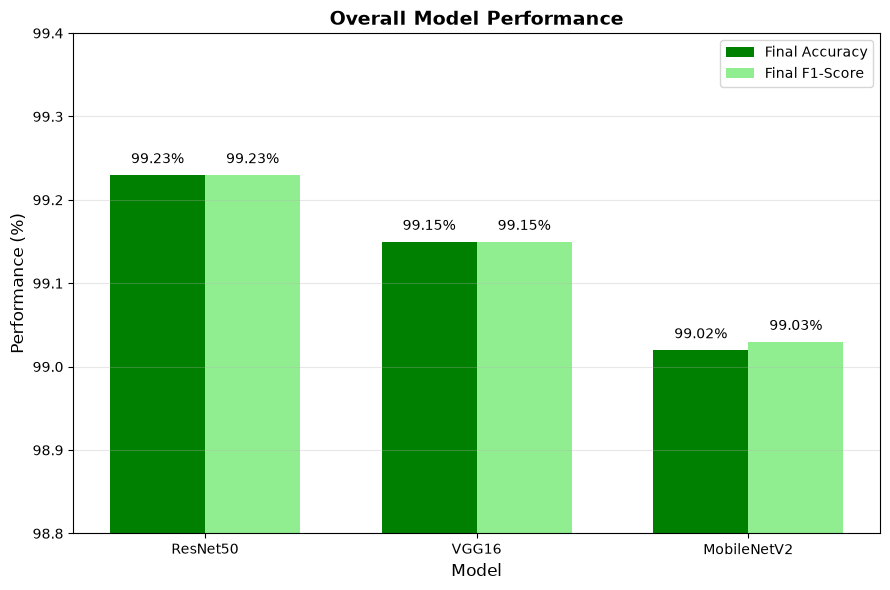

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Average final results across 4 datasets
models = ["ResNet50", "VGG16", "MobileNetV2"]

accuracy = [99.23, 99.15, 99.02]
f1_score = [99.23, 99.15, 99.03]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(9, 6))

# Green and light green bars
bars1 = plt.bar(
    x - width/2,
    accuracy,
    width,
    label="Final Accuracy",
    color="green"
)

bars2 = plt.bar(
    x + width/2,
    f1_score,
    width,
    label="Final F1-Score",
    color="lightgreen"
)

# Add values above bars
for bars in [bars1, bars2]:
    for bar in bars:
        value = bar.get_height()

        plt.text(
            bar.get_x() + bar.get_width()/2,
            value + 0.01,
            f"{value:.2f}%",
            ha="center",
            va="bottom",
            fontsize=10
        )

# Labels
plt.xlabel("Model", fontsize=12)
plt.ylabel("Performance (%)", fontsize=12)

plt.title(
    "Overall Model Performance",
    fontsize=14,
    fontweight="bold"
)

plt.xticks(x, models)

# Zoom in because the values are very close
plt.ylim(98.8, 99.4)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.legend()

plt.tight_layout()

# Save for PPT
plt.savefig(
    "overall_model_accuracy_f1_green.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()